# A Quick note about starry & limb darkening

starry has some weird limb darkening normalization

## Library and Data Setup

### Core Imports

In [1]:
#General imports
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from cmcrameri import cm
import faulthandler
faulthandler.enable()

# Directory structure - this is required for running jupyter in a folder
from pathlib import Path
maindir = str(Path(os.getcwd()).parent)
libdir  = os.path.join(maindir, 'lib')
if not libdir in sys.path:
    sys.path.append(maindir)
    sys.path.append(libdir)

# lib imports
from lib import eigen
from lib import utils
from lib import fitclass as fc
from lib.spotable import spotable as se

# import starry2 and set basic configuration
import starry2 as starry
starry.config.quiet = True
starry.config.lazy = True
sys.setrecursionlimit(10000) # starry seems to have a lot of recursion

### Importing each .py file

In [2]:
import create_eigens
import create_emaps
import create_rv
import create_real_null

### Reading Config File

In [3]:
fit = fc.Fit()
fit.read_config("../eridani.cfg")

cfg = fit.cfg

lmax = cfg.sim.lmax
udeg = cfg.star.udeg

# setting up units if present in cfg
if fit.cfg.star.units:
    scaler = 5.670374419e-8 * fit.cfg.star.teff**4
    power = int(np.floor(np.log10(scaler)))
    if power > 6:
        units = f"x10$^{power}$ W m$^{{-2}}$"
    else:
        units = f"W m$^{{-2}}$"
else:
    scaler = 1
    units = None

theta = np.linspace(-180,180,361)

### Python magic commands for better notebook displays

In [4]:
%matplotlib inline

## Testing no limb vs limb star

In [5]:
basic_star = utils.initstar(fit, lmax, udeg=[], include_rv=True)

limb_star = utils.initstar(fit, lmax, udeg=udeg, include_rv=True)
# print(basic_star.map.udeg)
# print(limb_star.map.udeg)

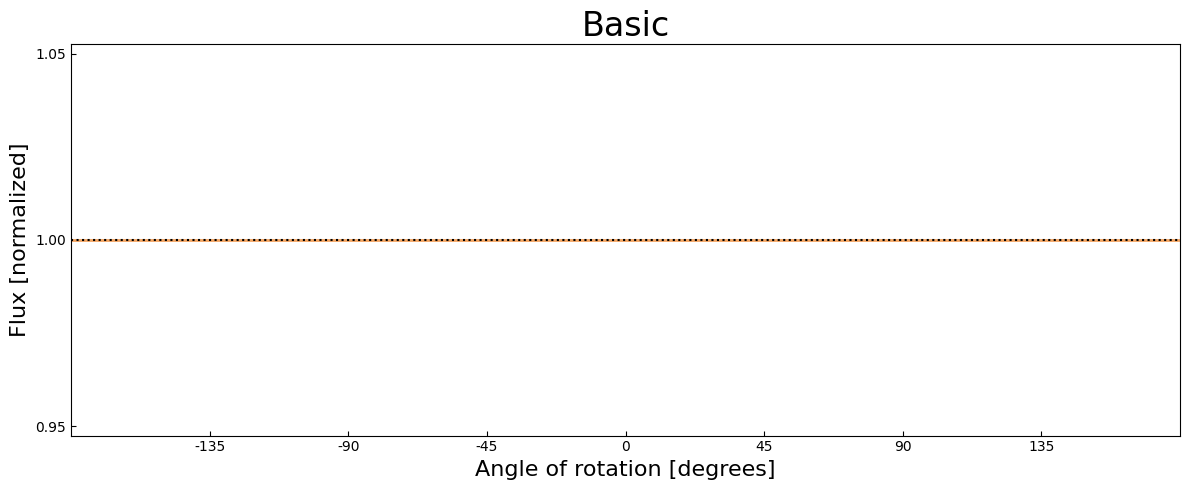

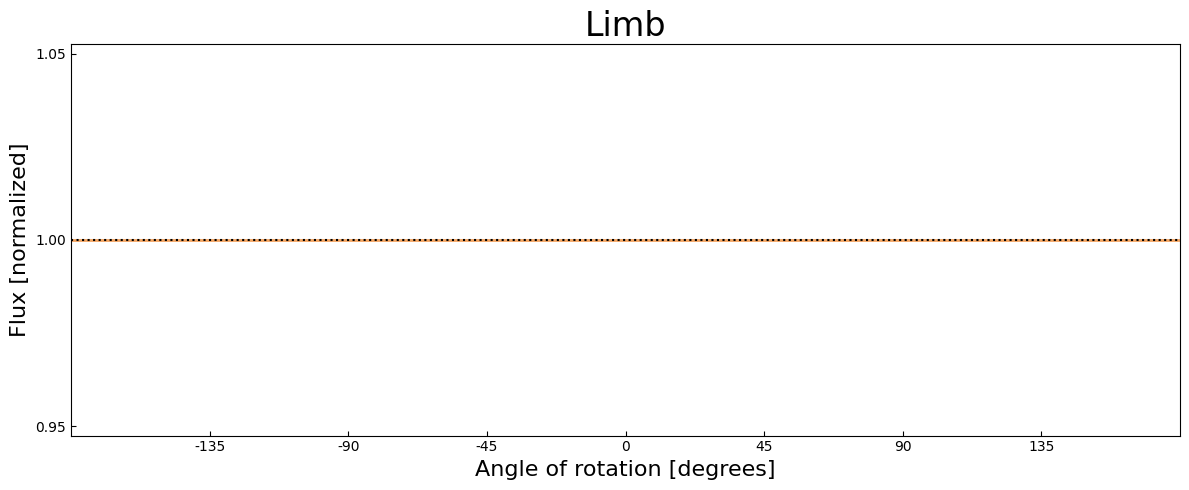

In [30]:
create_rv.flux_rv_line(basic_star,theta = theta, flux_only=True,title="Basic")
create_rv.flux_rv_line(limb_star,theta = theta, flux_only=True,title="Limb")

As you can see, the light curve is the exact same despite the limb differences!

This could be fine if the values of the map are different across the two, so let's check that

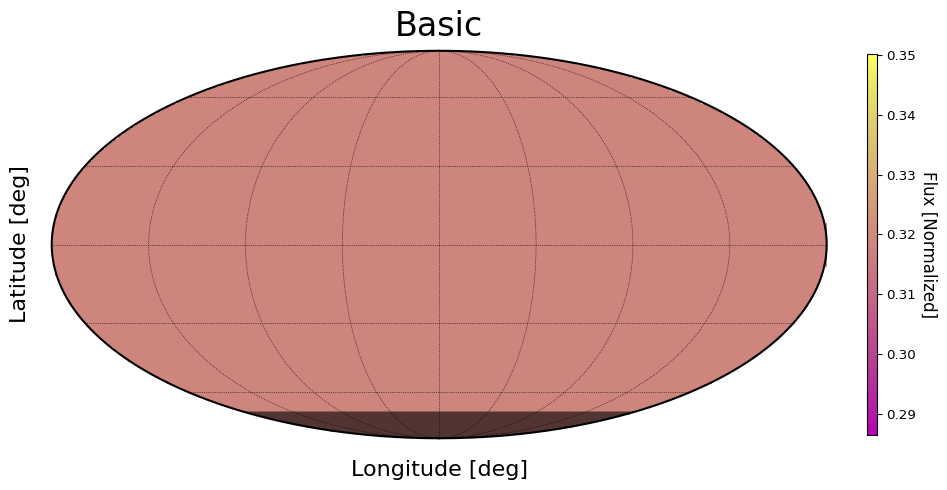

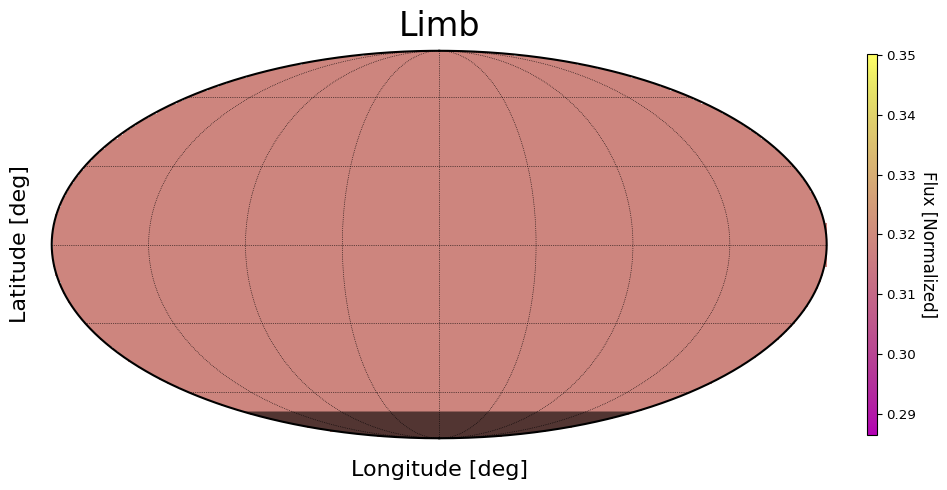

In [31]:
create_emaps.emap_plot(basic_star, proj='moll', cmap = cm.buda, title="Basic")

create_emaps.emap_plot(limb_star, proj='moll', cmap = cm.buda,title="Limb")

And with a normalized colorbar

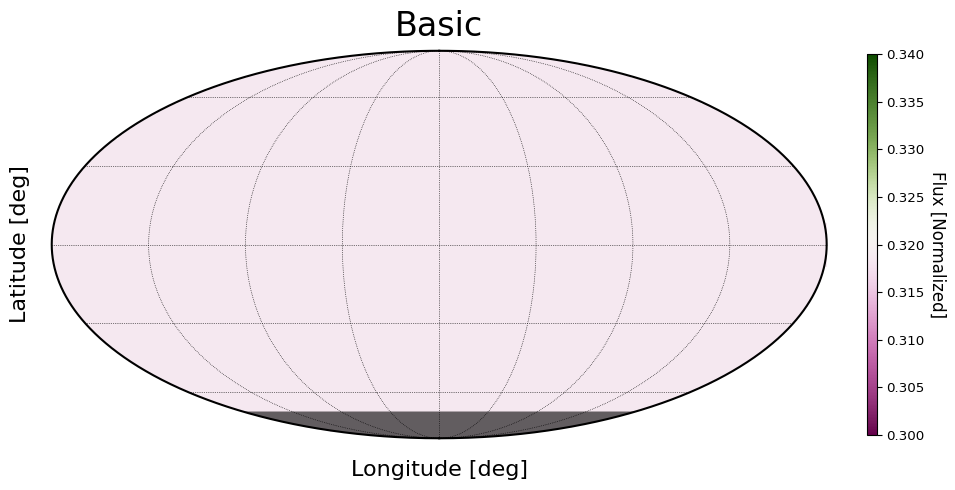

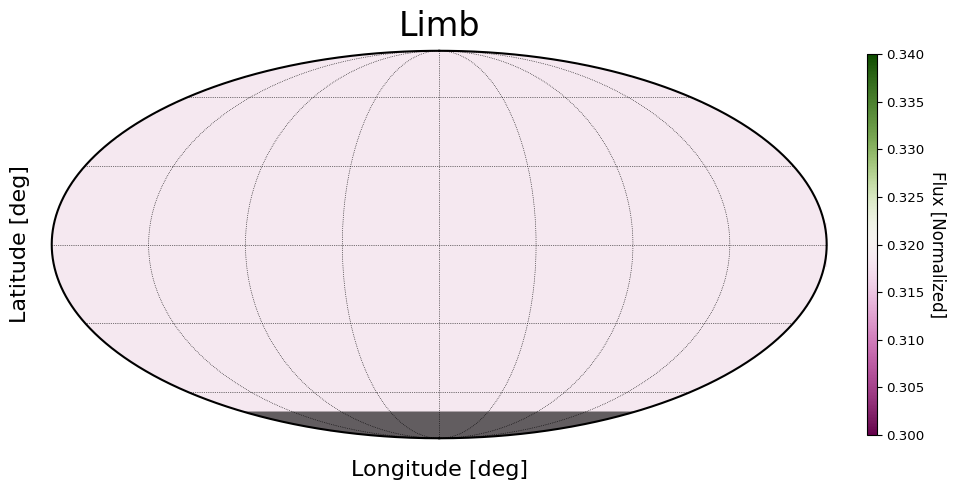

In [32]:
norm_cmap = mpl.colors.Normalize(vmin=0.30, vmax=0.34)

create_emaps.emap_plot(basic_star, proj='moll', cmap = cm.bam, cmap_norm=norm_cmap,title="Basic")

create_emaps.emap_plot(limb_star, proj='moll', cmap = cm.bam, cmap_norm=norm_cmap,title="Limb")


Those look the same, but we can be sure using starry's render feature

In [9]:
basic_values = basic_star.map.render(theta=0,projection="rect",rv=False).eval()
limb_values = limb_star.map.render(theta=0,projection="rect",rv=False).eval()

print(f"Are limb and basic using the same surface values: {np.allclose(basic_values, limb_values)}")

Are limb and basic using the same surface values: True


And the best way to show this is with the intensity curve

In [16]:
int_theta = np.linspace(-90,90,181)
basic_intensity = basic_star.map.intensity(lon=int_theta, lat=0,rv=False).eval()

limb_intensity = limb_star.map.intensity(lon=int_theta, lat=0, rv=False).eval()

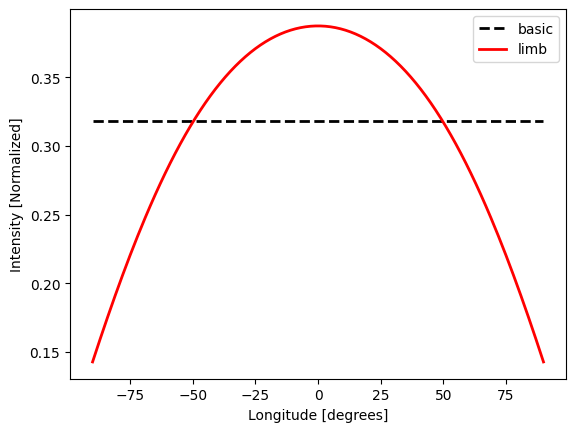

In [21]:
plt.plot(int_theta,basic_intensity, c="k", ls="--",lw="2",label="basic")
plt.plot(int_theta,limb_intensity, c="red", lw=2,label="limb")
plt.legend()
plt.xlabel("Longitude [degrees]")
plt.ylabel("Intensity [Normalized]")
plt.show()

## The Results:

This means there must be a factor applied in starry to "inflate" the flux of limb darkened maps.

But this factor IS NOT applied to features without limb darkening, like static projections through render.

Therefore, whenever we render in a map we should apply a factor to scale the limb darkening!

## Fixing Limb Darkening in Starry

Luckily we can do this pretty easily with the amplitude feature.  First let's fix that intensity issue:

In [22]:
int_theta = np.linspace(-90,90,181)
basic_intensity = basic_star.map.intensity(lon=int_theta, lat=0,rv=False).eval()

limb_intensity = limb_star.map.intensity(lon=int_theta, lat=0, rv=False).eval()

factor = np.max(basic_intensity) / np.max(limb_intensity)

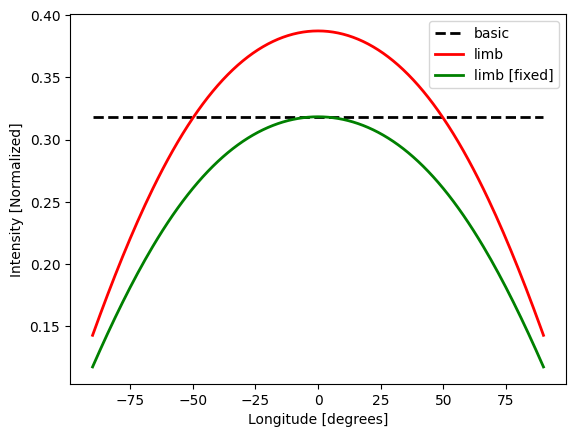

In [24]:
plt.plot(int_theta,basic_intensity, c="k", ls="--",lw="2",label="basic")
plt.plot(int_theta,limb_intensity, c="red", lw=2,label="limb")
plt.plot(int_theta,limb_intensity * factor, c="green", lw=2,label="limb [fixed]")
plt.legend()
plt.xlabel("Longitude [degrees]")
plt.ylabel("Intensity [Normalized]")
plt.show()

So using this factor, we can also fix the moll projections for earlier by setting the amp of limb_star

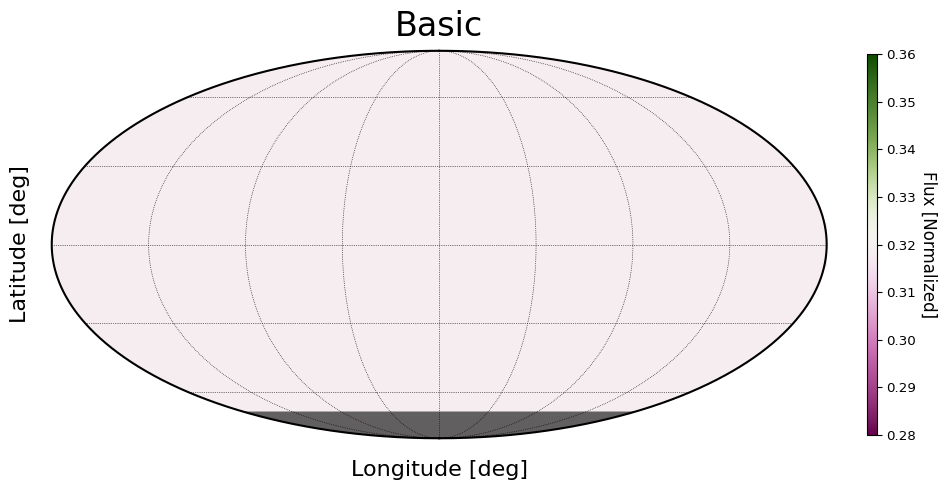

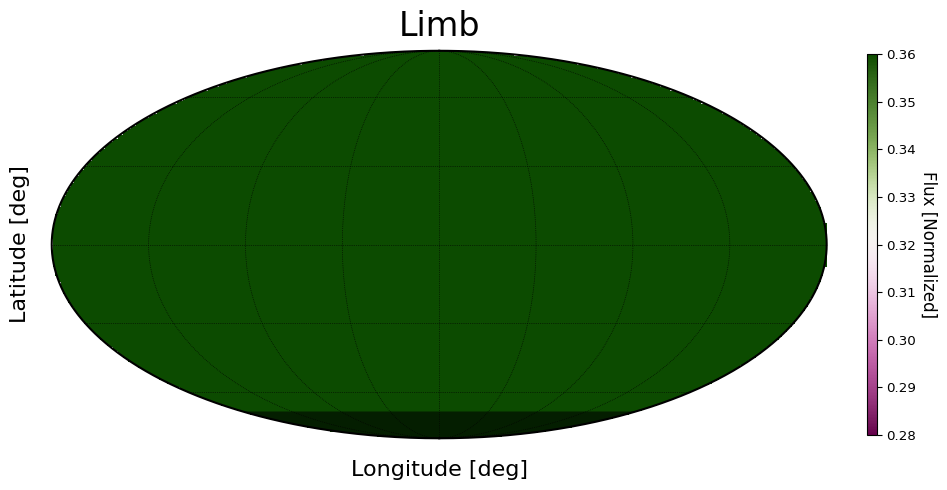

In [33]:
limb_star.map.amp /= factor

norm_cmap = mpl.colors.Normalize(vmin=0.28, vmax=0.36)

create_emaps.emap_plot(basic_star, proj='moll', cmap = cm.bam, cmap_norm=norm_cmap,title="Basic")

create_emaps.emap_plot(limb_star, proj='moll', cmap = cm.bam, cmap_norm=norm_cmap,title="Limb")


#don't forget to reset the factor though!
limb_star.map.amp *= factor


There we go!  Now the limb map is brighter than the basic map which would allow us to have the same light curve!

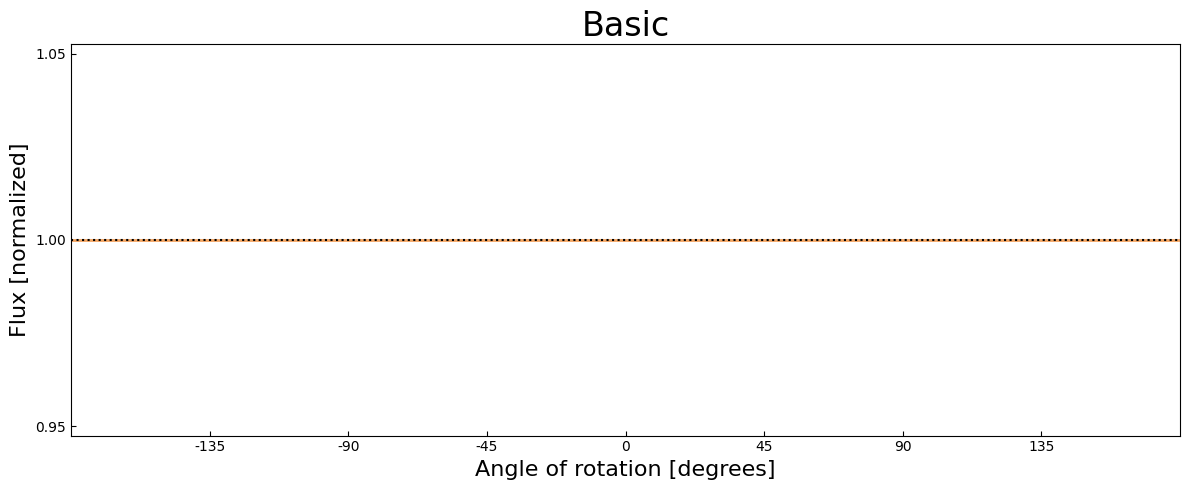

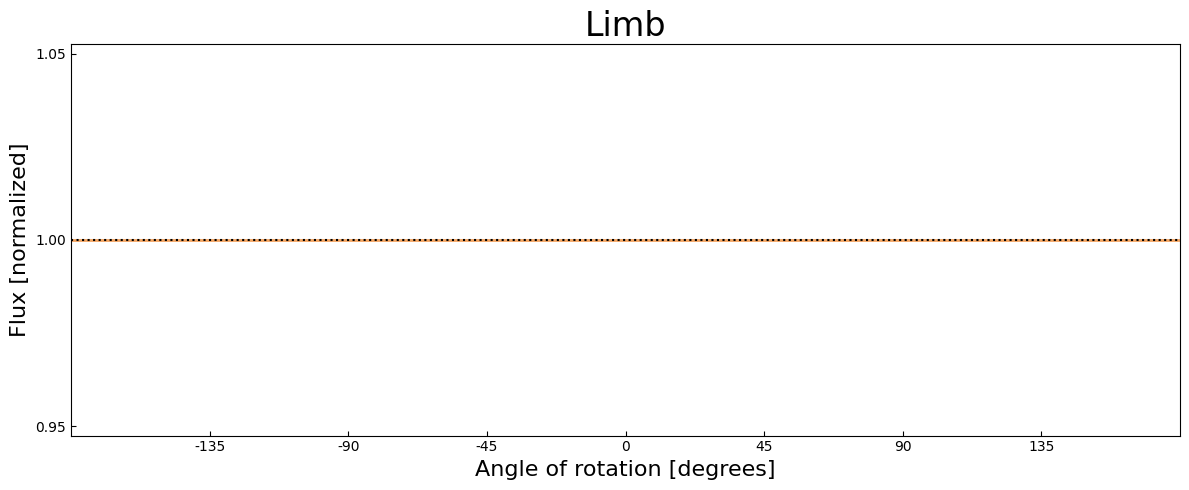

In [34]:
create_rv.flux_rv_line(basic_star,theta = theta, flux_only=True,title="Basic")
create_rv.flux_rv_line(limb_star,theta = theta, flux_only=True,title="Limb")

Alternatively, we could scale down the lightcurves and leave the moll projections alone through the inverse

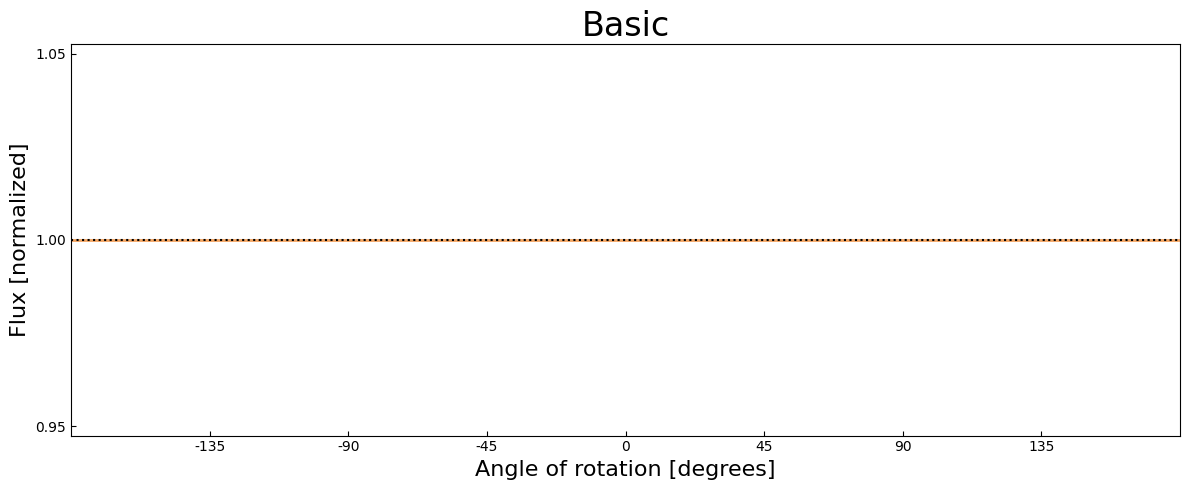

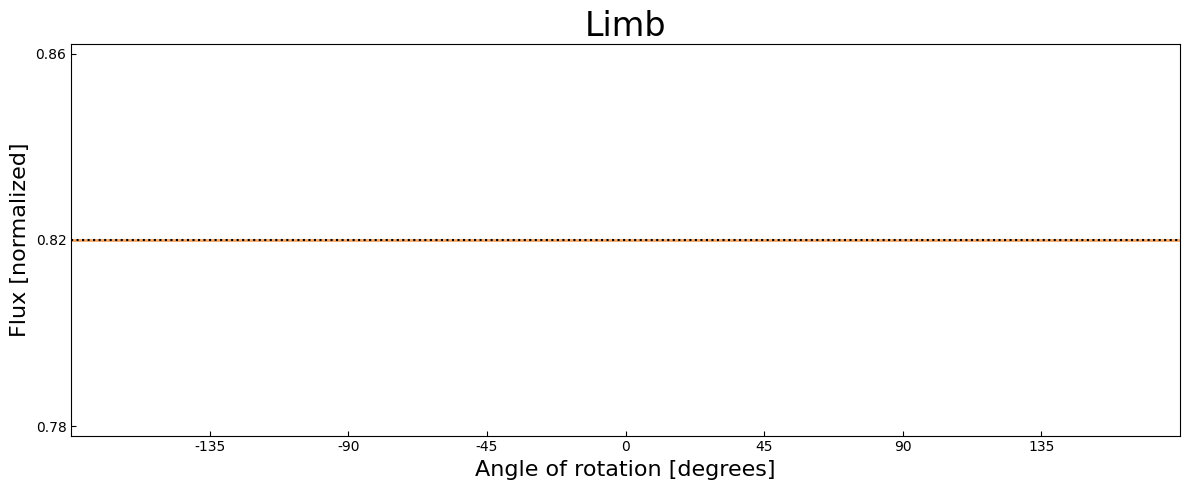

In [35]:
limb_star.map.amp *= factor

create_rv.flux_rv_line(basic_star,theta = theta, flux_only=True,title="Basic")
create_rv.flux_rv_line(limb_star,theta = theta, flux_only=True,title="Limb")

limb_star.map.amp /= factor


This leaves the projections being the exact same since not the limb map has a lower light curve

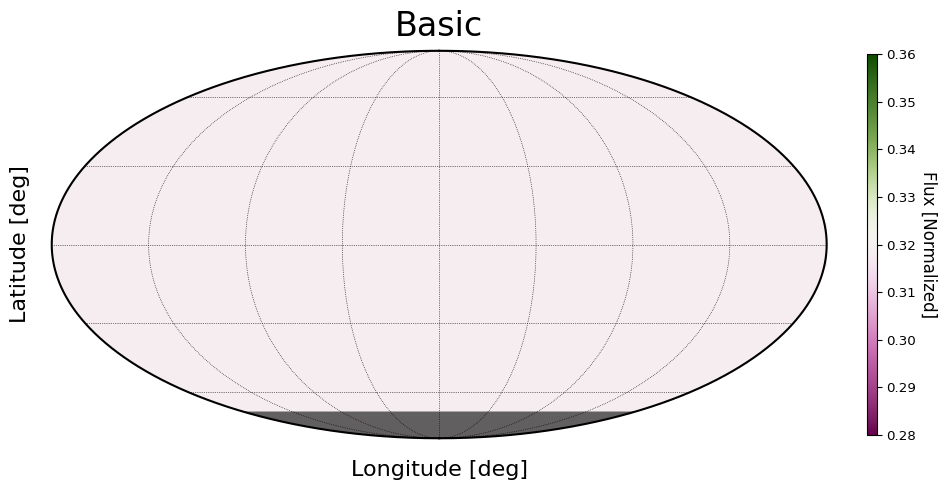

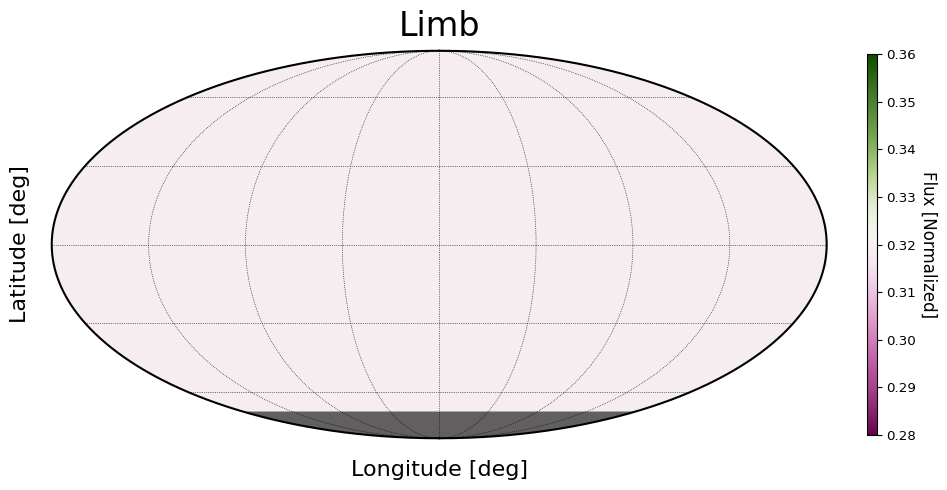

In [36]:
norm_cmap = mpl.colors.Normalize(vmin=0.28, vmax=0.36)

create_emaps.emap_plot(basic_star, proj='moll', cmap = cm.bam, cmap_norm=norm_cmap,title="Basic")

create_emaps.emap_plot(limb_star, proj='moll', cmap = cm.bam, cmap_norm=norm_cmap,title="Limb")

## Conclusion

Whether you scale down the features that account for limb darkening or scale up those that don't, it is important when working with starry and thus unspottable to account for limb darkening weirdness as we show here.

Now go do some mapping!